# **Предсказание скорости пристройства питомцев (PetFinder.my)**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
%matplotlib inline

# 0. Описание задачи

Данные взяты из соревнования Kaggle [PetFinder.my Adoption Prediction](https://www.kaggle.com/c/petfinder-adoption-prediction). PetFinder.my — малайзийский сайт, где приюты и волонтёры размещают анкеты бездомных кошек и собак. Каждая строка — одна анкета: вид животного, возраст, порода, окрас, пол, размер, здоровье, прививки, плата за пристройство, штат, число фото, текст описания и т.д.

Нужно по анкете предсказать **скорость пристройства** `AdoptionSpeed`:

| `AdoptionSpeed` | Значение |
|---|---|
| 0 | в день публикации объявления |
| 1 | в течение 1–7 дней |
| 2 | в течение 8–30 дней |
| 3 | в течение 31–90 дней |
| 4 | не забрали в течение 100 дней |

Это задача **классификации** с 5 классами. Классы упорядочены, но решаем её как обычную многоклассовую классификацию, как в примере с Adult.

Качество, как на лекции, оцениваем долей ошибок на обучающей и тестовой выборках и матрицами рассогласования. (В самом соревновании была другая метрика — quadratic weighted kappa, — но здесь мы её не используем.)

# 1. Загружаем данные

In [2]:
data_raw = pd.read_csv('train.csv/train.csv')

In [3]:
data_raw.shape

(14993, 24)

In [4]:
data_raw.head()

,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,FurLength,Vaccinated,Dewormed,Sterilized,Health,Quantity,Fee,State,RescuerID,VideoAmt,Description,PetID,PhotoAmt,AdoptionSpeed
0,2,Nibble,3,299,0,1,1,7,0,1,1,2,2,2,1,1,100,41326,8480853f516546f6cf33aa88cd76c379,0,Nibble is a 3+ month old ball of cuteness. He ...,86e1089a3,1.0,2
1,2,No Name Yet,1,265,0,1,1,2,0,2,2,3,3,3,1,1,0,41401,3082c7125d8fb66f7dd4bff4192c8b14,0,I just found it alone yesterday near my apartm...,6296e909a,2.0,0
2,1,Brisco,1,307,0,1,2,7,0,2,2,1,1,2,1,1,0,41326,fa90fa5b1ee11c86938398b60abc32cb,0,Their pregnant mother was dumped by her irresp...,3422e4906,7.0,3
3,1,Miko,4,307,0,2,1,2,0,2,1,1,1,2,1,1,150,41401,9238e4f44c71a75282e62f7136c6b240,0,"Good guard dog, very alert, active, obedience ...",5842f1ff5,8.0,2
4,1,Hunter,1,307,0,1,1,0,0,2,1,2,2,2,1,1,0,41326,95481e953f8aed9ec3d16fc4509537e8,0,This handsome yet cute boy is up for adoption....,850a43f90,3.0,2


In [5]:
data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 14993 entries, 0 to 14992
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Type           14993 non-null  int64  
 1   Name           13728 non-null  str    
 2   Age            14993 non-null  int64  
 3   Breed1         14993 non-null  int64  
 4   Breed2         14993 non-null  int64  
 5   Gender         14993 non-null  int64  
 6   Color1         14993 non-null  int64  
 7   Color2         14993 non-null  int64  
 8   Color3         14993 non-null  int64  
 9   MaturitySize   14993 non-null  int64  
 10  FurLength      14993 non-null  int64  
 11  Vaccinated     14993 non-null  int64  
 12  Dewormed       14993 non-null  int64  
 13  Sterilized     14993 non-null  int64  
 14  Health         14993 non-null  int64  
 15  Quantity       14993 non-null  int64  
 16  Fee            14993 non-null  int64  
 17  State          14993 non-null  int64  
 18  RescuerID      14

Признаки:

- `Type` — вид животного (1 — собака, 2 — кошка)
- `Name` — кличка (может отсутствовать)
- `Age` — возраст в месяцах
- `Breed1`, `Breed2` — основная и вторая порода (коды; 307 — метис (Mixed Breed), 264–266 — домашние длинно-, средне- и короткошёрстные кошки; `Breed2 = 0` — второй породы нет)
- `Gender` — пол (1 — самец, 2 — самка, 3 — группа животных разного пола)
- `Color1`, `Color2`, `Color3` — окрасы (коды 1–7: чёрный, коричневый, золотой, жёлтый, кремовый, серый, белый; 0 — нет)
- `MaturitySize` — размер во взрослом возрасте (1 — маленький, 2 — средний, 3 — большой, 4 — очень большой)
- `FurLength` — длина шерсти (1 — короткая, 2 — средняя, 3 — длинная)
- `Vaccinated`, `Dewormed`, `Sterilized` — привит / обработан от глистов / стерилизован (1 — да, 2 — нет, 3 — не уверен)
- `Health` — здоровье (1 — здоров, 2 — лёгкая травма, 3 — серьёзная травма)
- `Quantity` — количество животных в объявлении
- `Fee` — плата за пристройство (0 — бесплатно)
- `State` — штат Малайзии (код)
- `RescuerID` — идентификатор автора объявления (волонтёра, приюта)
- `VideoAmt`, `PhotoAmt` — количество видео и фото
- `Description` — текст объявления
- `PetID` — уникальный идентификатор объявления
- `AdoptionSpeed` — **целевой признак**

Типы признаков:
- количественные: `Age`, `Quantity`, `Fee`, `VideoAmt`, `PhotoAmt`;
- категориальные, записанные числами: `MaturitySize`, `FurLength`, `Health` — порядковые, `Type` — бинарный, остальные (`Breed1`, `Breed2`, `Gender`, `Color1`–`Color3`, `Vaccinated`, `Dewormed`, `Sterilized`, `State`) — номинальные;
- текстовые: `Name`, `Description`;
- идентификаторы: `RescuerID`, `PetID`.

Расшифровка кодов для графиков:

In [6]:
labels = {
    'Type':         {1: 'Dog', 2: 'Cat'},
    'Gender':       {1: 'Male', 2: 'Female', 3: 'Mixed'},
    'MaturitySize': {1: 'Small', 2: 'Medium', 3: 'Large', 4: 'Extra Large'},
    'FurLength':    {1: 'Short', 2: 'Medium', 3: 'Long'},
    'Vaccinated':   {1: 'Yes', 2: 'No', 3: 'Not Sure'},
    'Dewormed':     {1: 'Yes', 2: 'No', 3: 'Not Sure'},
    'Sterilized':   {1: 'Yes', 2: 'No', 3: 'Not Sure'},
    'Health':       {1: 'Healthy', 2: 'Minor Injury', 3: 'Serious Injury'},
}

Основные характеристики датасета (из задания 1):

| Характеристика | Значение |
|---|---|
| N (число объектов) | 14 993 |
| d (число признаков) | 23 |
| K (число классов) | 5 |
| Пропущенные значения | 8,5 % строк (`Name` — 1265, `Description` — 13) |
| Несбалансированность классов | 3 / 21 / 27 / 22 / 28 |
| Выбросы | ≈ 2 % строк (квантили 0.005 / 0.995) |
| Числовые / категориальные / текстовые / другие | 5 / 14 / 2 / 2 (идентификаторы) |

# 2. Обучающая и тестовая выборки

В тестовую выборку берём 25 % данных. Класс 0 очень маленький (меньше 3 %), поэтому разбиваем со стратификацией (`stratify=y`) — тогда доли классов в обеих выборках совпадут.

In [7]:
X = data_raw.drop('AdoptionSpeed', axis=1)
y = data_raw['AdoptionSpeed']

In [8]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

N_train, _ = X_train.shape
N_test,  _ = X_test.shape

N_train, N_test

(11244, 3749)

# 3. Визуализация и основные характеристики

Все характеристики считаем по обучающей выборке.

In [9]:
train = X_train.join(y_train)
num_columns = ['Age', 'Quantity', 'Fee', 'VideoAmt', 'PhotoAmt']
train[num_columns].describe()

,Age,Quantity,Fee,VideoAmt,PhotoAmt
count,11244.000000,11244.000000,11244.000000,11244.000000,11244.000000
mean,10.556475,1.586802,21.096318,0.056919,3.891587
std,18.472369,1.494640,75.347544,0.343109,3.501627
min,0.000000,1.000000,0.000000,0.000000,0.000000
25%,2.000000,1.000000,0.000000,0.000000,2.000000
50%,3.000000,1.000000,0.000000,0.000000,3.000000
75%,12.000000,1.000000,0.000000,0.000000,5.000000
max,255.000000,20.000000,2000.000000,8.000000,30.000000


- `Age` (в месяцах): среднее ≈ 10,6, а медиана — 3, т.е. в основном это котята и щенки, но есть животные и до 255 мес. (21 год).
- `Quantity`: обычно в анкете одно животное, но бывает и 20.
- `Fee`: минимум 75 % животных отдают бесплатно, максимум — 2000.
- `VideoAmt`: видео почти никто не прикладывает.
- `PhotoAmt`: в среднем ≈ 3,9 фото, медиана — 3.

In [10]:
train[['Name', 'Description', 'RescuerID', 'PetID']].describe()

,Name,Description,RescuerID,PetID
count,10309,11235,11244,11244
unique,7045,10592,4585,11244
top,Lucky,For Adoption,fa90fa5b1ee11c86938398b60abc32cb,cc628c147
freq,54,122,354,1


Клички почти уникальны, описания — тоже. У одного автора (`RescuerID`) бывает до 354 анкет — видимо, это приюты. `PetID` — просто идентификатор.

### Целевая переменная

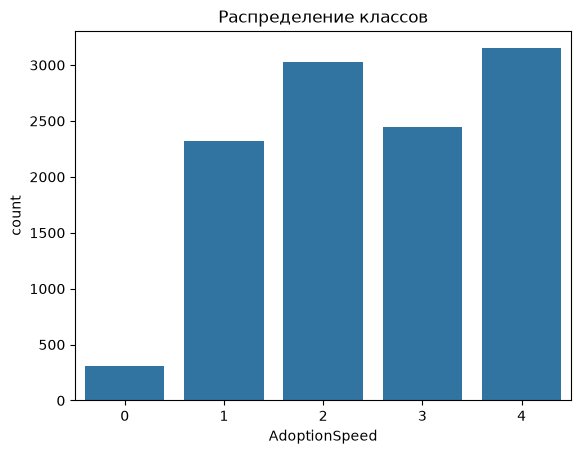

In [11]:
sns.countplot(x='AdoptionSpeed', data=train)
plt.title('Распределение классов')
pass

In [12]:
y_train.value_counts(normalize=True).sort_index().round(3)

AdoptionSpeed
0    0.027
1    0.206
2    0.269
3    0.217
4    0.280
Name: proportion, dtype: float64

Классы 1–4 встречаются примерно одинаково часто (21–28 %), а класс 0 («забрали в день публикации») — меньше 3 %. Если всегда отвечать «4» (самый частый класс), ошибка будет 72 %.

### Числовые признаки

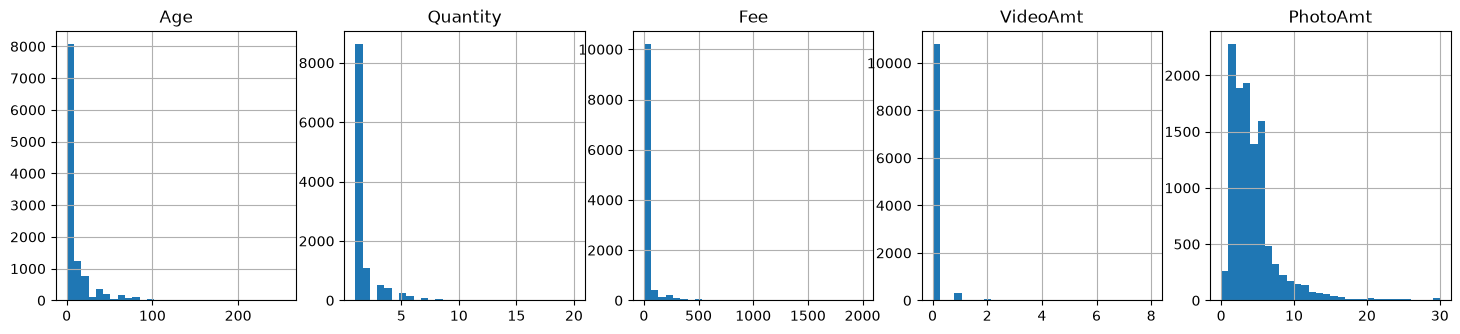

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, c in zip(axes, num_columns):
    ax.hist(train[c], bins=30)
    ax.set_title(c)
    ax.grid()
pass

Все числовые признаки сильно скошены вправо: почти все значения у нуля и длинный хвост. Сравним средние в разных классах:

In [14]:
train.groupby('AdoptionSpeed')[num_columns].mean().round(2)

,Age,Quantity,Fee,VideoAmt,PhotoAmt
AdoptionSpeed,,,,,
0,9.97,1.41,25.77,0.07,3.44
1,8.59,1.47,23.24,0.04,3.69
2,8.67,1.56,21.72,0.06,4.09
3,10.30,1.54,18.57,0.07,4.62
4,14.08,1.75,20.43,0.05,3.32


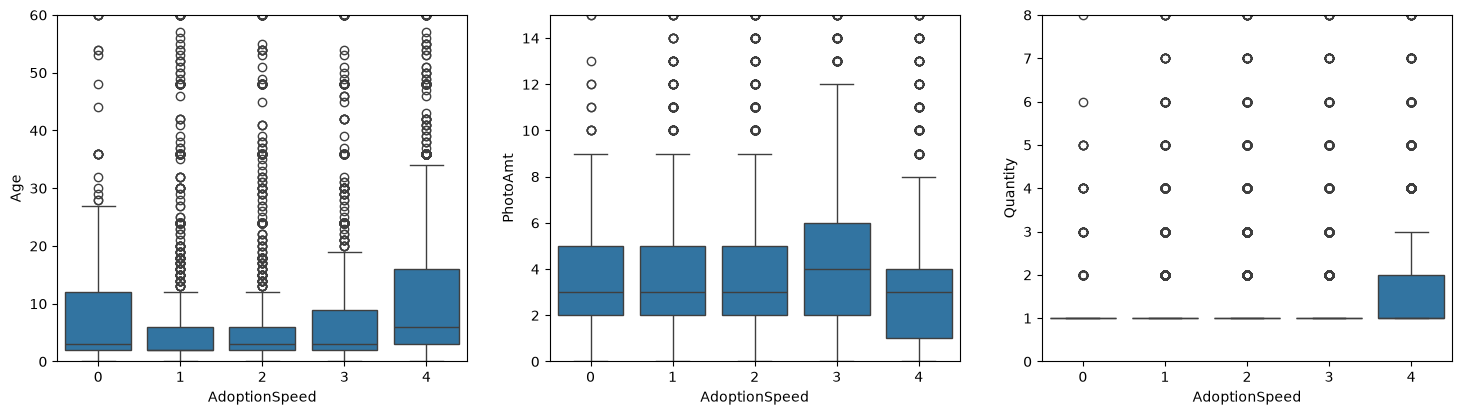

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.boxplot(x='AdoptionSpeed', y='Age', data=train, ax=axes[0])
axes[0].set_ylim(0, 60)
sns.boxplot(x='AdoptionSpeed', y='PhotoAmt', data=train, ax=axes[1])
axes[1].set_ylim(0, 15)
sns.boxplot(x='AdoptionSpeed', y='Quantity', data=train, ax=axes[2])
axes[2].set_ylim(0, 8)
pass

- Взрослых животных забирают хуже: в классе 4 средний возраст — 14 мес., в остальных — 9–10.
- У «зависших» анкет (класс 4) меньше фото: в среднем 3,3 против 4,1–4,6 у классов 2 и 3.
- Анкеты с несколькими животными чаще попадают в класс 4.
- При этом распределения в разных классах сильно перекрываются.

### Категориальные признаки

Среднее значение `AdoptionSpeed` (чем меньше, тем быстрее забирают) для разных значений признаков:

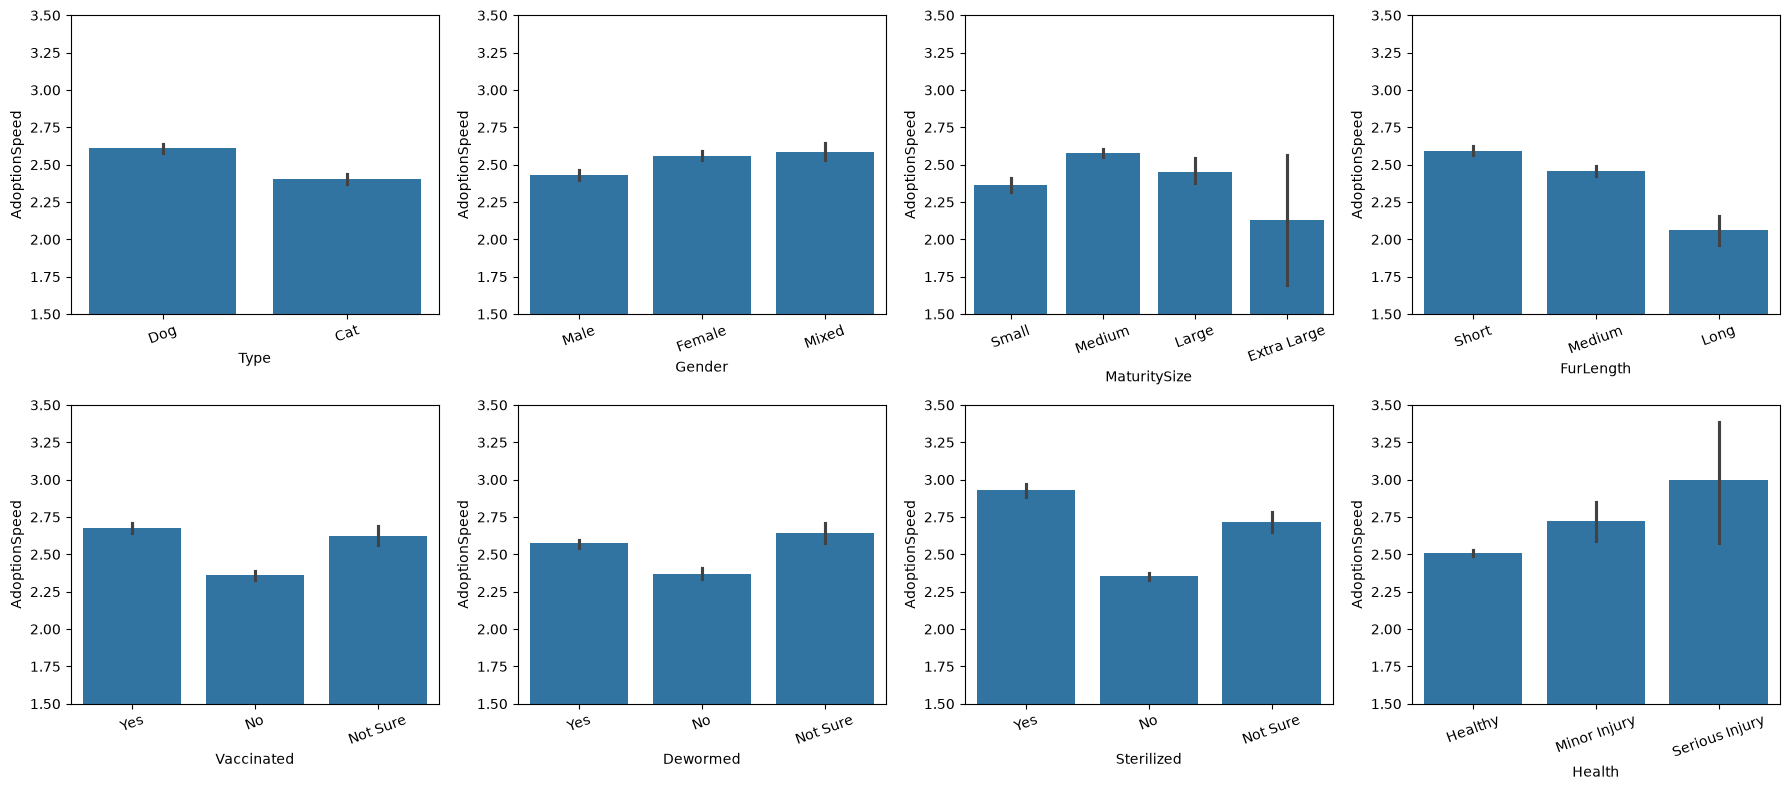

In [16]:
cat_view = ['Type', 'Gender', 'MaturitySize', 'FurLength', 'Vaccinated', 'Dewormed', 'Sterilized', 'Health']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), cat_view):
    sns.barplot(x=train[c].map(labels[c]), y=train['AdoptionSpeed'], order=list(labels[c].values()), ax=ax)
    ax.set_xlabel(c)
    ax.set_ylim(1.5, 3.5)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
pass

- Кошек забирают быстрее, чем собак, а длинношёрстных — быстрее, чем короткошёрстных.
- Здоровых — быстрее, чем травмированных (но травмированных животных очень мало).
- Странно, что привитых и стерилизованных животных забирают медленнее. Возможно, дело в возрасте: стерилизуют обычно уже взрослых животных, а их, как видно выше, забирают хуже.

In [17]:
train['State'].value_counts(normalize=True).head().round(3)

State
41326    0.583
41401    0.255
41327    0.057
41336    0.034
41330    0.027
Name: proportion, dtype: float64

In [18]:
train['Breed1'].value_counts().head(10)

Breed1
307    4464
266    2728
265     916
299     261
264     220
292     180
285     170
141     157
205     148
179     124
Name: count, dtype: int64

In [19]:
train['Breed1'].nunique(), train['Breed2'].nunique()

(161, 125)

Почти все анкеты (84 %) — из двух штатов с кодами 41326 и 41401 (по описанию датасета это Селангор и Куала-Лумпур). У `Breed1` 161 значение, но 40 % — собаки-метисы (код 307) и ещё около трети — беспородные кошки (264–266), а большинство пород встречается редко. При кодировании редкие породы и штаты объединим.

### Диаграмма рассеивания

Как в примере с Adult, добавим к дискретным значениям небольшой шум, чтобы точки не сливались, и посмотрим на два «крайних» класса: 1 (забрали за неделю) и 4 (не забрали за 100 дней).

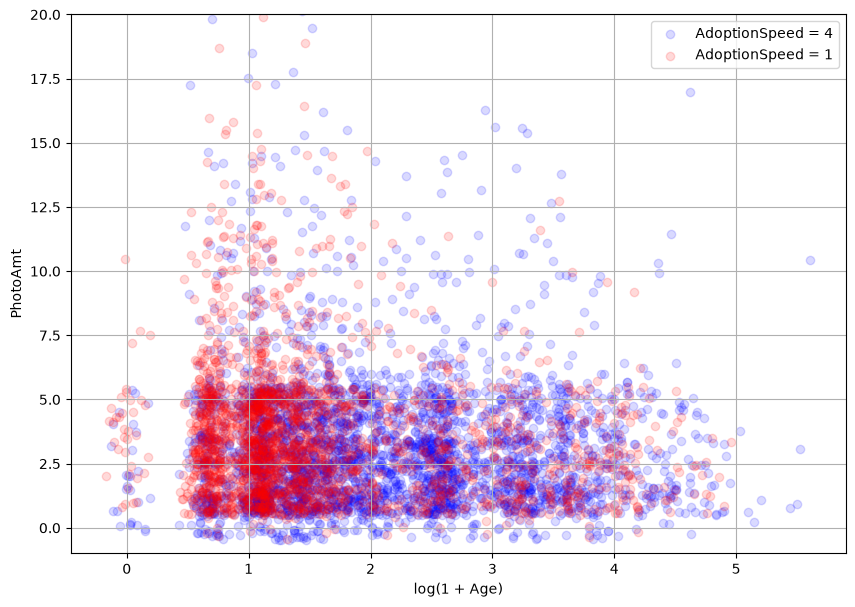

In [20]:
np.random.seed(0)
age_rnd   = np.log1p(train['Age']) + 0.1 * np.random.randn(len(train))
photo_rnd = train['PhotoAmt'] + np.random.rand(len(train)) - .5

plt.figure(figsize=(10, 7))
for cls, color in [(4, 'b'), (1, 'r')]:
    plt.scatter(age_rnd[train['AdoptionSpeed'] == cls], photo_rnd[train['AdoptionSpeed'] == cls],
                alpha=0.15, color=color, label=f'AdoptionSpeed = {cls}')
plt.xlabel('log(1 + Age)')
plt.ylabel('PhotoAmt')
plt.ylim(-1, 20)
plt.legend()
plt.grid()
pass

Облака почти полностью перекрываются, видна только тенденция: «быстрых» (красных) точек больше среди малышей. Значит, задача трудная, и высокой точности ждать не стоит.

### Корреляционная матрица

Для номинальных признаков с произвольными кодами (`Breed1`, `State`) корреляция смысла не имеет, поэтому берём только числовые, порядковые и бинарные:

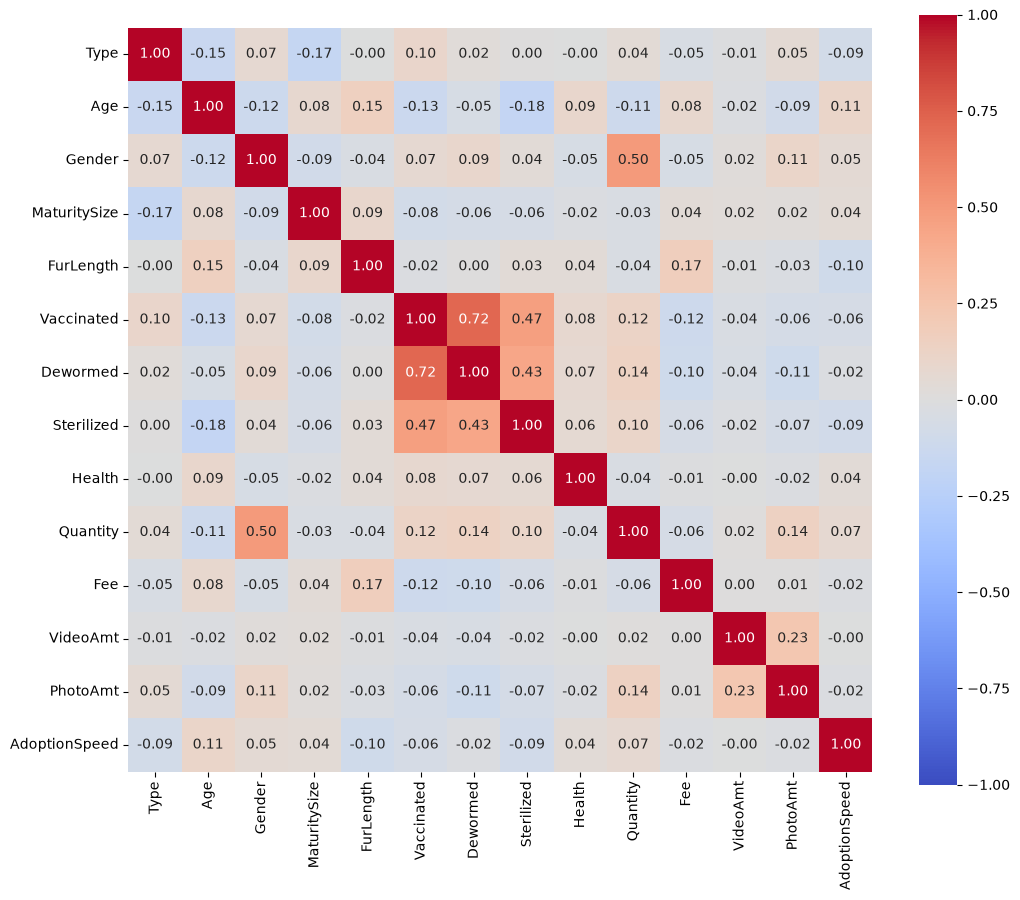

In [21]:
corr_columns = ['Type', 'Age', 'Gender', 'MaturitySize', 'FurLength', 'Vaccinated', 'Dewormed',
                'Sterilized', 'Health', 'Quantity', 'Fee', 'VideoAmt', 'PhotoAmt', 'AdoptionSpeed']
corr_mat = train[corr_columns].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_mat, square=True, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm')
pass

- Сильнее всего коррелируют `Vaccinated` и `Dewormed` (0,72): животное обычно и прививают, и обрабатывают от глистов. `Gender` и `Quantity` (0,50) связаны, потому что `Gender = 3` означает группу животных.
- С `AdoptionSpeed` все корреляции слабые (по модулю не больше 0,11), сильнее всего — с возрастом и длиной шерсти.

# 4. Выбросы

In [22]:
X_train[num_columns].quantile([0.005, .01, .05, .1, .5, .9, .95, .99, .995])

,Age,Quantity,Fee,VideoAmt,PhotoAmt
0.005,0.0,1.0,0.0,0.0,0.000
0.010,0.0,1.0,0.0,0.0,0.000
0.050,1.0,1.0,0.0,0.0,1.000
0.100,1.0,1.0,0.0,0.0,1.000
0.500,3.0,1.0,0.0,0.0,3.000
0.900,29.0,3.0,50.0,0.0,7.000
0.950,48.0,5.0,150.0,0.0,10.000
0.990,84.0,7.0,350.0,2.0,19.000
0.995,108.0,9.0,500.0,2.0,23.785


Хвосты длинные: например, 99 % значений `Age` — до 108 мес. (9 лет), а максимум — 255 мес. (21 год, скорее всего ошибка ввода). Проверим правило $[Q_1-1.5\cdot{\rm IQR},\, Q_3+1.5\cdot{\rm IQR}]$ из лекции — какая доля объектов окажется выбросами по каждому признаку:

In [23]:
for c in num_columns:
    Q1, Q3 = X_train[c].quantile([.25, .75])
    IQR = Q3 - Q1
    share = ((X_train[c] < Q1 - 1.5*IQR) | (X_train[c] > Q3 + 1.5*IQR)).mean()
    print(c, IQR, round(share, 3))

Age 10.0 0.101
Quantity 0.0 0.231
Fee 0.0 0.156
VideoAmt 0.0 0.039
PhotoAmt 3.0 0.061


Здесь правило не подходит: у `Quantity`, `Fee` и `VideoAmt` межквартильный размах равен 0, и выбросами оказываются все анкеты с платой, видео или несколькими животными. Поэтому возьмём квантили $0.005$ и $0.995$ и выбросим из обучающей выборки строки, которые за них выходят:

In [24]:
q_low  = X_train[num_columns].quantile(0.005)
q_high = X_train[num_columns].quantile(0.995)

rows_to_drop = X_train[((X_train[num_columns] < q_low) | (X_train[num_columns] > q_high)).any(axis=1)].index
len(rows_to_drop)

230

In [25]:
X_train = X_train.drop(rows_to_drop)
y_train = y_train.drop(rows_to_drop)
N_train, _ = X_train.shape
N_train

11014

Удалено 230 объектов (2 %). Из тестовой выборки удалять объекты нельзя, поэтому там просто обрежем значения по тем же границам (например, возраст 255 мес. станет 108):

In [26]:
X_test[num_columns] = X_test[num_columns].clip(q_low, q_high, axis=1)
X_test[num_columns].describe().loc[['min', 'max']]

,Age,Quantity,Fee,VideoAmt,PhotoAmt
min,0.0,1.0,0.0,0.0,0.000
max,108.0,9.0,500.0,2.0,23.785


# 5. Пропущенные значения

In [27]:
data_raw.isna().sum()

Type                0
Name             1265
Age                 0
Breed1              0
Breed2              0
Gender              0
Color1              0
Color2              0
Color3              0
MaturitySize        0
FurLength           0
Vaccinated          0
Dewormed            0
Sterilized          0
Health              0
Quantity            0
Fee                 0
State               0
RescuerID           0
VideoAmt            0
Description        13
PetID               0
PhotoAmt            0
AdoptionSpeed       0
dtype: int64

Пропуски есть только в текстах: у 1265 животных нет клички, у 13 — описания. Медианой такое не заполнишь, а отсутствие клички само может что-то значить. Кроме того, есть «скрытые» пропуски — клички вроде «No Name» или «Unknown»:

In [28]:
no_name_pattern = 'no name|noname|unknown|not named|unnamed|nameless'
name = X_train['Name'].fillna('').str.lower().str.strip()
name[name.str.contains(no_name_pattern)].value_counts().head(10)

Name
no name                                  38
no name yet                              17
unknown                                  11
unnamed                                   5
nameless                                  5
no names yet                              4
noname                                    2
(no name)                                 2
4 kittens open for adoption (no name)     1
unnamed.                                  1
Name: count, dtype: int64

Такие клички тоже будем считать отсутствующими. Пропуски заполним пустой строкой, а в п. 6 сделаем из текстов признаки «есть кличка» и «длина описания». Значение «Not Sure» у `Vaccinated`, `Dewormed`, `Sterilized` оставим отдельной категорией.

In [29]:
for D in (X_train, X_test):
    D['Name'] = D['Name'].fillna('')
    D['Description'] = D['Description'].fillna('')

X_train.isna().sum().sum(), X_test.isna().sum().sum()

(np.int64(0), np.int64(0))

# 6. Обработка категориальных и текстовых признаков

Сначала сделаем несколько новых признаков:
- `HasName` — есть ли кличка;
- `DescLength` — длина описания в словах;
- `RescuerCount` — сколько анкет у автора: так можно отличить крупные приюты от частных лиц (сам `RescuerID` как категория бесполезен);
- `NColors` — число окрасов вместо `Color2` и `Color3`;
- `HasBreed2` — указана ли вторая порода (помесь) вместо `Breed2`.

`PetID` удаляем. Порядковые `MaturitySize`, `FurLength`, `Health` оставляем числами.

In [30]:
# число анкет автора считаем по всем данным: целевая переменная здесь не используется
rescuer_count = pd.concat([X_train, X_test])['RescuerID'].value_counts()

for D in (X_train, X_test):
    name = D['Name'].str.lower().str.strip()
    D['HasName']      = ((name != '') & ~name.str.contains(no_name_pattern)).astype(int)
    D['DescLength']   = D['Description'].str.split().str.len()
    D['RescuerCount'] = D['RescuerID'].map(rescuer_count)
    D['NColors']      = (D[['Color1', 'Color2', 'Color3']] > 0).sum(axis=1)
    D['HasBreed2']    = ((D['Breed2'] != 0) & (D['Breed2'] != D['Breed1'])).astype(int)

drop_cols = ['Name', 'Description', 'RescuerID', 'PetID', 'Breed2', 'Color2', 'Color3']
X_train = X_train.drop(drop_cols, axis=1)
X_test  = X_test.drop(drop_cols, axis=1)

Номинальные признаки бинаризуем `OneHotEncoder`'ом, как на лекции. Чтобы не плодить почти пустые столбцы, редкие породы и штаты (меньше 100 анкет в обучающей выборке) объединим в одну категорию.

In [31]:
from sklearn.preprocessing import OneHotEncoder
cat_columns = ['Type', 'Gender', 'Color1', 'Vaccinated', 'Dewormed', 'Sterilized', 'Breed1', 'State']
enc = OneHotEncoder(drop='if_binary', sparse_output=False, min_frequency=100, handle_unknown='infrequent_if_exist')
enc.fit(X_train[cat_columns])

dummies_train = pd.DataFrame(enc.transform(X_train[cat_columns]), columns=enc.get_feature_names_out(), index=X_train.index)
dummies_test  = pd.DataFrame(enc.transform(X_test[cat_columns]),  columns=enc.get_feature_names_out(), index=X_test.index)
X_train = pd.concat((X_train.drop(cat_columns, axis=1), dummies_train), axis=1)
X_test  = pd.concat((X_test.drop(cat_columns, axis=1), dummies_test), axis=1)
X_train.shape, X_test.shape

((11014, 54), (3749, 54))

# 7. Нормализация

Признаки сильно различаются по масштабу: `Fee` — сотни, `DescLength` — десятки и сотни слов, а порядковые признаки — от 1 до 3–4. kNN считает расстояния, так что без нормализации не обойтись. Скошенные признаки сначала прологарифмируем ($x \to \log(1+x)$), чтобы сжать длинные хвосты, а затем стандартизируем все числовые и порядковые признаки по обучающей выборке. Dummy-признаки оставляем 0/1, как в примере Adult.

In [32]:
num_features = ['Age', 'Quantity', 'Fee', 'VideoAmt', 'PhotoAmt', 'DescLength', 'RescuerCount',
                'NColors', 'MaturitySize', 'FurLength', 'Health']
log_features = ['Age', 'Quantity', 'Fee', 'VideoAmt', 'PhotoAmt', 'DescLength', 'RescuerCount']

X_train[log_features] = np.log1p(X_train[log_features])
X_test[log_features]  = np.log1p(X_test[log_features])

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train[num_features])
X_train[num_features] = scaler.transform(X_train[num_features])
X_test[num_features]  = scaler.transform(X_test[num_features])

# 8. Классификатор ближайших соседей

kNN требуется в задании и разбирался на лекции, поэтому начинаем с него. Он ничего не предполагает о форме границы между классами, но для него все признаки равноправны, а с редкими классами он справляется плохо — это мы ещё увидим.

Как в примере Adult, начнём с $k = 10$:

In [33]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](5,)","[0,1,2,3,4]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [34]:
y_train_predict = knn.predict(X_train)
y_test_predict  = knn.predict(X_test)

err_train = np.mean(y_train != y_train_predict)
err_test  = np.mean(y_test  != y_test_predict)

errors = {'kNN, k = 10': (err_train, err_test)}
err_train, err_test

(np.float64(0.4884692209914654), np.float64(0.6367031208322219))

Для сравнения — ошибка классификатора, который всегда отвечает самым частым классом:

In [35]:
err_const = np.mean(y_test != y_train.mode()[0])
y_train.mode()[0], err_const

(np.int64(4), np.float64(0.7201920512136569))

# 9. Ошибки, матрицы рассогласования и подбор $k$

In [36]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, y_test_predict))

[[  5  32  31   9  26]
 [  2 284 254  80 153]
 [  1 275 371 141 221]
 [  2 187 280 179 167]
 [  2 178 232 114 523]]


Строки — истинные классы, столбцы — предсказанные. При $k = 10$ ошибка на обучающей выборке (0,49) заметно меньше, чем на тестовой (0,64): модель переобучается, хотя константу (0,72) обыгрывает. Класс 0 почти не угадывается (5 из 103).

### Выбор $k$

Число соседей выбираем 5-фолдовой кросс-валидацией (тестовую выборку не трогаем):

In [37]:
from sklearn.model_selection import GridSearchCV
k_arr = [1, 3, 5, 10, 15, 20, 30, 40, 50, 70, 100, 150, 200, 300]
grid = GridSearchCV(KNeighborsClassifier(), param_grid={'n_neighbors': k_arr}, cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

best_cv_err = 1 - grid.best_score_
best_n_neighbors = grid.best_params_['n_neighbors']
print(best_cv_err, best_n_neighbors)

0.6156718008594506 70


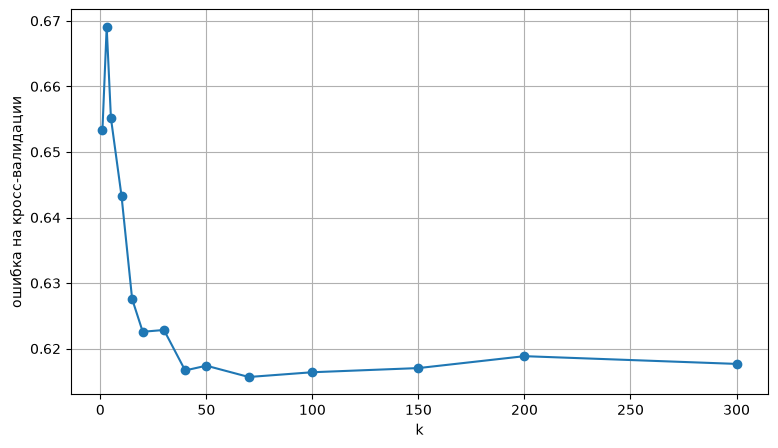

In [38]:
plt.figure(figsize=(9, 5))
plt.plot(k_arr, 1 - grid.cv_results_['mean_test_score'], 'o-')
plt.xlabel('k')
plt.ylabel('ошибка на кросс-валидации')
plt.grid()
pass

При маленьких $k$ модель переобучается и ошибка на кросс-валидации высокая. По мере увеличения $k$ ошибка падает и примерно с $k \approx 40$ выходит на плато около 0,62. Минимум — при $k = 70$ (0,616), но от 40 до 300 ошибка почти не меняется. Такое большое $k$ говорит о том, что классы сильно перемешаны и нужно «голосование» многих соседей.

In [39]:
knn = KNeighborsClassifier(n_neighbors=best_n_neighbors).fit(X_train, y_train)

y_train_predict = knn.predict(X_train)
y_test_predict  = knn.predict(X_test)

err_train = np.mean(y_train != y_train_predict)
err_test  = np.mean(y_test  != y_test_predict)
errors[f'kNN, k = {best_n_neighbors}'] = (err_train, err_test)
err_train, err_test

(np.float64(0.5808970401307427), np.float64(0.6172312616697786))

Матрицы рассогласования на обучающей и тестовой выборках:

In [40]:
print(confusion_matrix(y_train, y_train_predict))
print()
print(confusion_matrix(y_test, y_test_predict))

[[   0   73   96   19  115]
 [   0  685  817  131  654]
 [   0  458 1352  304  850]
 [   0  279  845  448  822]
 [   0  241  547  147 2131]]

[[  0  33  28   6  36]
 [  0 208 304  32 229]
 [  0 171 405  95 338]
 [  0 113 286 139 277]
 [  0  97 204  65 683]]


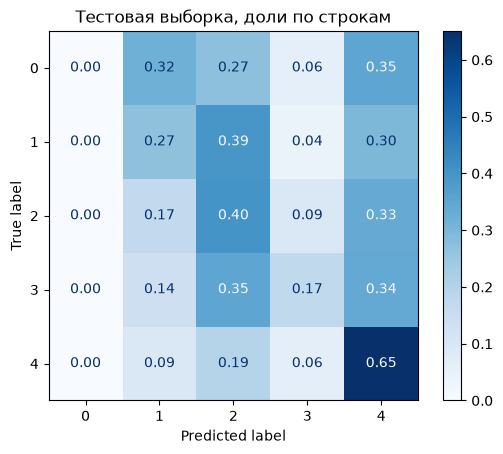

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, y_test_predict, normalize='true', values_format='.2f', cmap='Blues')
plt.title('Тестовая выборка, доли по строкам')
pass

При $k = 70$:
- ошибка на обучающей выборке 0,58, на тестовой — 0,62: переобучения почти нет, и тестовая ошибка меньше, чем при $k = 10$ (0,64);
- класс 0 модель не предсказывает вообще (первый столбец нулевой): среди 70 соседей объекты этого класса никогда не составляют большинства;
- лучше всего узнаётся класс 4 (65 % объектов), хуже всего — классы 1 и 3 (27 % и 17 %), их часто относят к классу 2;
- доля правильных ответов — 0,38: немного, но лучше константы (0,28).

# 10. Другие классификаторы

Попробуем методы из лекции: логистическую регрессию, SVC, случайный лес и градиентный бустинг.

In [42]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression(max_iter=2000).fit(X_train, y_train)

err_train = np.mean(y_train != logreg.predict(X_train))
err_test  = np.mean(y_test  != logreg.predict(X_test))
errors['Логистическая регрессия'] = (err_train, err_test)
print(err_train, err_test)

0.5835300526602506 0.6014937316617764


In [43]:
from sklearn.svm import SVC
svc = SVC().fit(X_train, y_train)

err_train = np.mean(y_train != svc.predict(X_train))
err_test  = np.mean(y_test  != svc.predict(X_test))
errors['SVC'] = (err_train, err_test)
print(err_train, err_test)

0.48120573815144363 0.5884235796212324


In [44]:
from sklearn import ensemble
rf = ensemble.RandomForestClassifier(n_estimators=500, random_state=42).fit(X_train, y_train)

err_train = np.mean(y_train != rf.predict(X_train))
err_test  = np.mean(y_test  != rf.predict(X_test))
errors['Random Forest'] = (err_train, err_test)
print(err_train, err_test)

0.002360631923007082 0.5713523606295012


In [45]:
gbt = ensemble.GradientBoostingClassifier(random_state=42).fit(X_train, y_train)

err_train = np.mean(y_train != gbt.predict(X_train))
err_test  = np.mean(y_test  != gbt.predict(X_test))
errors['Градиентный бустинг'] = (err_train, err_test)
print(err_train, err_test)

0.5105320501180316 0.5884235796212324


In [46]:
pd.DataFrame.from_dict(errors, orient='index', columns=['err_train', 'err_test']).round(3)

,err_train,err_test
"kNN, k = 10",0.488,0.637
"kNN, k = 70",0.581,0.617
Логистическая регрессия,0.584,0.601
SVC,0.481,0.588
Random Forest,0.002,0.571
Градиентный бустинг,0.511,0.588


- Все модели лучше константы, но ни у одной ошибка не опускается ниже 0,57 — задача действительно трудная.
- Лучший — случайный лес (0,571), хотя на обучающей выборке он почти не ошибается (0,002), т.е. сильно переобучается. У SVC и бустинга — 0,588, у логистической регрессии — 0,601.
- kNN (0,617) — самый слабый: для него все признаки равноправны, хотя полезны они по-разному.

### Значимость признаков (случайный лес)

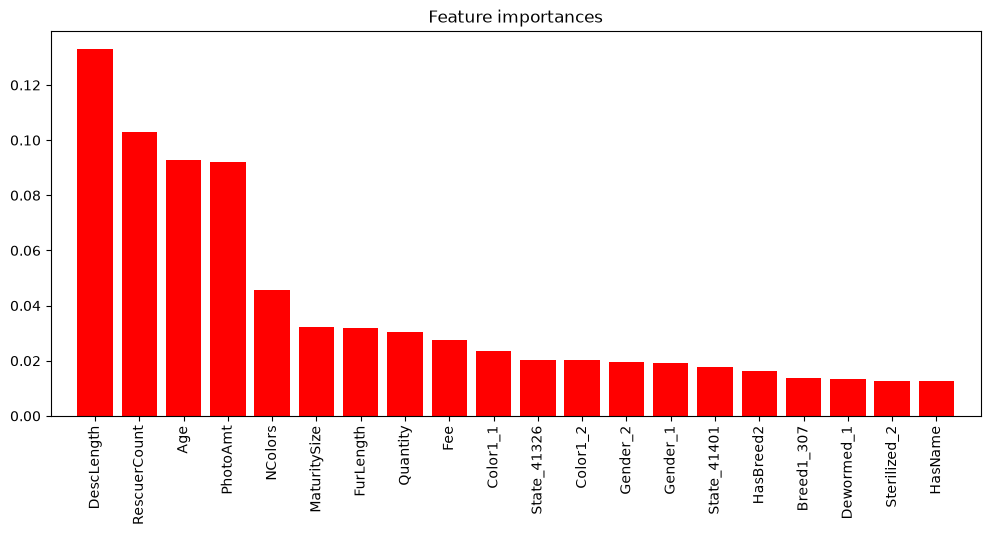

In [47]:
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
feature_names = X_train.columns

d_first = 20
plt.figure(figsize=(12, 5))
plt.title('Feature importances')
plt.bar(range(d_first), importances[indices[:d_first]], align='center', color='r')
plt.xticks(range(d_first), feature_names[indices[:d_first]], rotation=90)
plt.xlim([-1, d_first])
pass

Самые важные признаки — длина описания, число анкет у автора, возраст и число фото. Два из них (`DescLength` и `RescuerCount`) — наши новые признаки из п. 6.

# 11. Борьба с несбалансированностью классов

Класс 0 (меньше 3 %) модели почти не предсказывают: при минимизации общей ошибки выгоднее никогда его не называть. Попробуем задать веса классов `class_weight='balanced'` — тогда ошибка на объекте редкого класса штрафуется сильнее. Такой параметр есть у логистической регрессии и случайного леса.

In [48]:
logreg_bal = LogisticRegression(max_iter=2000, class_weight='balanced').fit(X_train, y_train)

err_train = np.mean(y_train != logreg_bal.predict(X_train))
err_test  = np.mean(y_test  != logreg_bal.predict(X_test))
errors['Логистическая регрессия, balanced'] = (err_train, err_test)
print(err_train, err_test)
print(confusion_matrix(y_test, logreg_bal.predict(X_test)))

0.6468131469039404 0.6673779674579888
[[ 43  26   9  10  15]
 [213 215 121 102 122]
 [172 219 179 216 223]
 [115 136 153 258 153]
 [181 117  61 138 552]]


In [49]:
rf_bal = ensemble.RandomForestClassifier(n_estimators=500, class_weight='balanced', random_state=42).fit(X_train, y_train)

err_train = np.mean(y_train != rf_bal.predict(X_train))
err_test  = np.mean(y_test  != rf_bal.predict(X_test))
errors['Random Forest, balanced'] = (err_train, err_test)
print(err_train, err_test)
print(confusion_matrix(y_test, rf_bal.predict(X_test)))

0.002542218994007627 0.5684182448652975


[[ 13  41  17   7  25]
 [ 16 333 188  78 158]
 [ 10 253 323 167 256]
 [  6 169 176 263 201]
 [  8 157 100  98 686]]


Логистическая регрессия с весами находит класс 0 гораздо чаще (43 объекта из 103, а kNN не находил ни одного), но общая ошибка выросла с 0,601 до 0,667: модель стала называть класс 0 и для многих объектов других классов. У случайного леса эффект слабее: класс 0 угадан у 13 объектов из 103, общая ошибка почти та же (0,568). Так что выбор зависит от цели: если важно находить «мгновенно пристраиваемых» животных, нужна балансировка, а если общая точность — лучше без неё. Ещё можно было бы объединить классы 0 и 1, раз класс 0 такой маленький.

# 12. Исключение коррелированных переменных

Если два признака сильно коррелированы, kNN фактически учитывает одну и ту же информацию с двойным весом. Посмотрим, какие пары после кодирования коррелируют сильнее 0,7 по модулю:

In [50]:
corr_proc = X_train.corr()
corr_proc.where(np.triu(np.abs(corr_proc) > 0.7, k=1)).stack().dropna().sort_values()

Dewormed_1    Dewormed_2     -0.774460
Vaccinated_1  Vaccinated_2   -0.773041
Gender_1      Gender_2       -0.745943
Type_2        Breed1_307     -0.740265
Sterilized_1  Sterilized_2   -0.726888
Quantity      Gender_3        0.764028
Vaccinated_3  Dewormed_3      0.841263
dtype: float64

Пары вида `Dewormed_1` – `Dewormed_2` — просто следствие one-hot кодирования (если «да», то не «нет»). Содержательные пары: `Vaccinated_3` – `Dewormed_3` (0,84), `Quantity` – `Gender_3` (0,76: «группа разного пола» — это несколько животных) и `Type_2` – `Breed1_307` (−0,74: метисы бывают только у собак). Удалим все `Dewormed_*`, а также `Gender_3` и `Breed1_307`:

In [51]:
drop_columns = [c for c in X_train.columns if c.startswith('Dewormed_')] + ['Gender_3', 'Breed1_307']
X_train2 = X_train.drop(drop_columns, axis=1)
X_test2  = X_test.drop(drop_columns, axis=1)

knn2 = KNeighborsClassifier(n_neighbors=best_n_neighbors).fit(X_train2, y_train)
print('kNN:', np.mean(y_train != knn2.predict(X_train2)), np.mean(y_test != knn2.predict(X_test2)))

logreg2 = LogisticRegression(max_iter=2000).fit(X_train2, y_train)
print('LR: ', np.mean(y_train != logreg2.predict(X_train2)), np.mean(y_test != logreg2.predict(X_test2)))

kNN: 0.583984020337752 0.615364097092558


LR:  0.5838024332667514 0.6036276340357428


Разницы почти нет: тестовая ошибка kNN 0,617 → 0,615, логистической регрессии 0,601 → 0,604. Корреляции здесь умеренные, и удалённые признаки, видимо, несут и свою информацию — удалять их смысла нет.

# 13. Выводы

In [52]:
pd.DataFrame.from_dict(errors, orient='index', columns=['err_train', 'err_test']).sort_values('err_test').round(3)

,err_train,err_test
"Random Forest, balanced",0.003,0.568
Random Forest,0.002,0.571
SVC,0.481,0.588
Градиентный бустинг,0.511,0.588
Логистическая регрессия,0.584,0.601
"kNN, k = 70",0.581,0.617
"kNN, k = 10",0.488,0.637
"Логистическая регрессия, balanced",0.647,0.667


Мы предсказывали по анкете с PetFinder.my, как быстро заберут животное: это классификация с 5 классами, причём класс 0 очень редкий (меньше 3 %). Ни один признак сам по себе классы не разделяет: быстрее забирают малышей, кошек и длинношёрстных животных, а также анкеты с большим числом фото, но распределения в классах сильно перекрываются. После обработки (из текстов сделали признаки «есть кличка» и «длина описания», номинальные признаки бинаризовали, скошенные прологарифмировали и всё стандартизировали) kNN с оптимальным $k = 70$ дал ошибку 0,62 на тесте против 0,72 у константы, но класс 0 не предсказывает совсем. Лучше всех оказался случайный лес (около 0,57), затем SVC и градиентный бустинг (0,59), а kNN — самый слабый из рассмотренных методов. Важнее всего длина описания, число анкет у автора, возраст и число фото. Веса классов помогают находить класс 0, но обычно ценой роста общей ошибки, а удаление коррелированных признаков ничего не дало. Улучшить результат, наверное, можно, если вытащить больше информации из текстов описаний и учесть порядок классов.